In [1]:
import numpy as np
import scipy as sp
import math
from scipy import stats
import itertools as it

# plots will be shown inline
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.mlab as mlab

from scipy.stats import geom


# Calcolo combinatorio
Il calcolo combinatorio riguarda la valutazione delle possibili combinazioni in cui si possono ordinare una serie di elementi.

Il calcolo combinatorio si basa sul
**Principio Fondamentale del Calcolo Combinatorio:**
se una scelta può essere fatta in $s_1$ modi diversi, e per ciascuno di essi, una seconda scelta può essere fatta in $s_2$ modi diversi, e così a seguire fino alla t-esima scelta con $s_t$ modi diversi, **allora** il numero di sequenze possibile è:
$$
s_1\cdot s_2\cdot \dots  \cdot s_t
$$

Python ha delle funzioni predefinite per il calcolo combinatorio nelle librerie:
- scipy.special
- itertools


## Disposizioni

Si chiamano disposizioni (con ripetizione) il numero di modi in cui possiamo *disporre* $n$ elementi in $k$ caselle. Poiché per ogni posizione $k$ abbiamo a disposizione $n$ elementi tra cui scegliere, allora il numero di disposizioni è
$$
D_{n,k} = n^k
$$
Per visulizzare le disposizioni possiamo scrivere

In [2]:
# n  il numero di elementi da disporre
n = 4
l = range(0, n)
# (l1, l2) le k caselle, in questo caso 2 in cui vogliamo disporre
# i nostri elementi
disp_rep = [(l1, l2) for l1 in l for l2 in l]
print('disposizioni possibili:', disp_rep)
print('numero di disposizioni:', len(disp_rep))


disposizioni possibili: [(0, 0), (0, 1), (0, 2), (0, 3), (1, 0), (1, 1), (1, 2), (1, 3), (2, 0), (2, 1), (2, 2), (2, 3), (3, 0), (3, 1), (3, 2), (3, 3)]
numero di disposizioni: 16


## Disposizioni semplici
disposizioni senza ripetizione di $n$ elementi in $k$ calselle. Nella prima casella ho $n$ scelte possibili, nella seconda ho $n-1$ scelte possibili poiché non potrò scegliere l'elemento selezionato in nella prima casella, e cosi via fino ad arrivare alla $k$-esima casella dove potrò inserire uno tra $n-k+1$ possibili elementi, dunque il numero di disposizioni semplici sono:
$$
d_{n,k} = n\cdot(n-1)\dots(n-k+1) = \frac{n!}{(n-k)!}
$$
possiamo calcolare il numero di disposizioni nella maniera seguente:

In [3]:
n = 4
k = 2
math.factorial(n)/math.factorial(n-k)

12.0

In [4]:
disp_norep = [d for d in disp_rep if len(d)==len(set(d))]
# nota che data una sequenza d set(d) da l'insieme degli elenti di d
# gli elementi uguali sono contati una volta sola, qundi nel if vengono
# selezionati solo le sequenze di elementi diversi
print('possibili disposizioni semplici:', disp_norep)
print('numero di disposizioni semplici:', len(disp_norep))


possibili disposizioni semplici: [(0, 1), (0, 2), (0, 3), (1, 0), (1, 2), (1, 3), (2, 0), (2, 1), (2, 3), (3, 0), (3, 1), (3, 2)]
numero di disposizioni semplici: 12


## Permutazioni semplici
Le permutazioni semplici, solo con elementi distinguibili tra loro, corrispondono ai possibili ordinamenti di $n$ elementi in $n$ caselle, ovvero al numero di disposizioni semplici:
$$
P_n = d_{n,n} = n!
$$

In [5]:
a = [1, 2, 3]
p = it.permutations(a)
print('possibili permutazioni:', list(p))

possibili permutazioni: [(1, 2, 3), (1, 3, 2), (2, 1, 3), (2, 3, 1), (3, 1, 2), (3, 2, 1)]


## Combinazioni semplici
Sono le combinazioni senza ripetizione che corrispondono alle disposizioni sempici di $n$ elementi  in $k$ caselle dove però non si presta attenzione all'ordinamento, ovvero le sequenze:
$$
(a, b, c) = (b, a, c) = (c, a, b) = \cdots
$$
vengono considerate uguali. Per ottenere il numero di combinazoni semplici si dovrà dividere per il numero di permutazioni possibili:
$$
c_{n,k} = \frac{d_{n,k}}{p_{k}} = \frac{n!}{(n-k)!k!}
$$

In [6]:
# il numero di di combinazioni degli elementi di a presi a 2 a 2 e'
sp.special.comb(len(a), 2)

3.0

In [7]:
list(it.combinations(a,2))

[(1, 2), (1, 3), (2, 3)]

In [8]:

# infine le combinazioni con ripetizioni
list(it.combinations_with_replacement(a,2))

[(1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3)]

# Distribuzione Geometrica

In [9]:
# plots will be shown inline
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.mlab as mlab
import numpy as np
from scipy.stats import geom

In [10]:
p = 0.2
mean, var = geom.stats(p, moments='mv') #mv sta per media e varianza
sd = np.sqrt(var)
print('E[x | G(p = {0:.1f})]   = {1:.1f}'.format(p, mean))
print('var[x | G(p = {0:.1f})] = {1:.1f}'.format(p, var))

E[x | G(p = 0.2)]   = 5.0
var[x | G(p = 0.2)] = 20.0


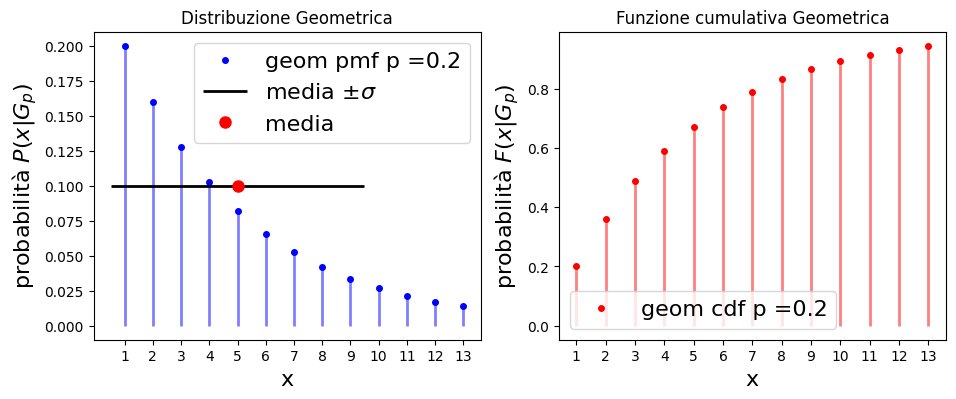

In [11]:
x = np.arange(1, geom.ppf(0.95, p))
# nota l'uso del quanntile geom.ppf che da il valore di x per cui la cumulativa
# vale 0.95
plt.figure(1, [11, 4])
plt.subplot(121)
# grafico della pmf
plt.plot(x, geom.pmf(x, p), 'bo', ms=4, label='geom pmf p ={0:.1f}'.format(p))
plt.vlines(x, 0, geom.pmf(x, p), colors='b', lw=2, alpha=0.5)
# grafico di media e sd
plt.hlines(0.1, mean-sd, mean+sd, colors='black', lw=2, label='media $\pm \sigma$')
plt.plot(mean, 0.1, 'ro', ms=8, label='media')
plt.title('Distribuzione Geometrica')
plt.xlabel("x", fontsize=16)
plt.ylabel("probabilità $P(x| G_p)$", fontsize=16)
plt.legend( fontsize=16)
t = plt.xticks(x)

plt.subplot(122)
plt.plot(x, geom.cdf(x, p), 'ro', ms=4, label='geom cdf p ={0:.1f}'.format(p))
plt.vlines(x, 0, geom.cdf(x, p), colors='r', lw=2, alpha=0.5)
plt.title('Funzione cumulativa Geometrica')
plt.xlabel("x", fontsize=16)
plt.ylabel("probabilità $F(x| G_p)$", fontsize=16)
plt.legend( fontsize=16)
t = plt.xticks(x)

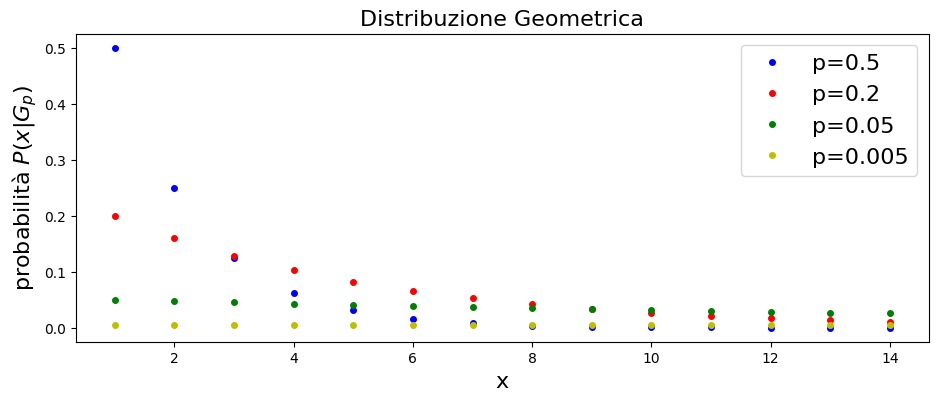

In [12]:
plt.figure(2, [11, 4])
x=np.arange(1,15)
plt.plot(x, geom.pmf(x, 0.5), 'b.', ms=8, label='p=0.5')
plt.plot(x, geom.pmf(x, 0.2), 'r.', ms=8, label='p=0.2')
plt.plot(x, geom.pmf(x, 0.05), 'g.', ms=8, label='p=0.05')
plt.plot(x, geom.pmf(x, 0.005), 'y.', ms=8, label='p=0.005')
plt.title('Distribuzione Geometrica', fontsize=16)
plt.xlabel("x", fontsize=16)
plt.ylabel("probabilità $P(x| G_p)$", fontsize=16)
plt.legend(fontsize=16)

# Distribuzione Binomiale

In [13]:
from scipy.stats import binom
n, p = 10, 0.35
mean, var = binom.stats(n, p, moments='mv') #mv sta per media e varianza
sd = np.sqrt(var)
print('E[x | B(p = {0:.1f})]   = {1:.1f}'.format(p, mean))
print('var[x | B(p = {0:.1f})] = {1:.1f}'.format(p, var))

E[x | B(p = 0.3)]   = 3.5
var[x | B(p = 0.3)] = 2.3


In [14]:
x = np.arange(0, n+1)
b = binom(n, p)


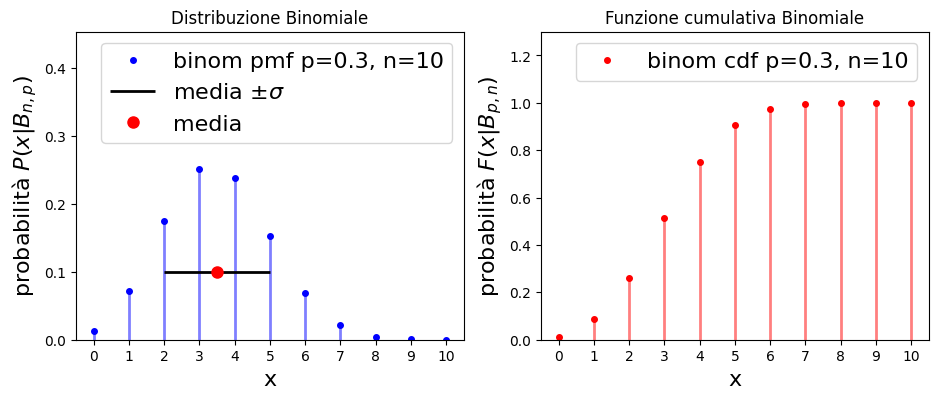

In [15]:
plt.figure(1, [11, 4])
plt.subplot(121)
# grafico della pmf
plt.plot(x, b.pmf(x), 'bo', ms=4,
         label='binom pmf p={0:.1f}, n={1:1d}'.format(p,n))
plt.vlines(x, 0, b.pmf(x), colors='b', lw=2, alpha=0.5)
# grafico di media e sd
plt.hlines(0.1, mean-sd, mean+sd,
           colors='black', lw=2, label='media $\pm \sigma$')
plt.plot(mean, 0.1, 'ro', ms=8, label='media')
plt.title('Distribuzione Binomiale')
plt.xlabel("x", fontsize=16)
plt.ylabel("probabilità $P(x| B_{n,p})$", fontsize=16)
plt.legend( fontsize=16)
t = plt.xticks(x)
plt.ylim(0, np.max(b.pmf(x))*1.8)

plt.subplot(122)
plt.plot(x, b.cdf(x), 'ro', ms=4,
         label='binom cdf p={0:.1f}, n={1:1d}'.format(p,n))
plt.vlines(x, 0, b.cdf(x), colors='r', lw=2, alpha=0.5)
plt.title('Funzione cumulativa Binomiale')
plt.xlabel("x", fontsize=16)
plt.ylabel("probabilità $F(x| B_{p,n})$", fontsize=16)
plt.ylim(0, 1.3)
plt.legend( fontsize=16)
t = plt.xticks(x)

## Confronto con gaussiana

In [16]:
def confronto(n=10, p=0.5):
    mean = n*p
    sigma = np.sqrt(n*p*(1-p))
    xmin = 0
    xmax = n
    x = np.arange(xmin, xmax)
    plt.plot(x, stats.binom.pmf(x, n, p), marker=".",
        color='black', alpha=0.75, linestyle='none',
        label=r'binomiale n={0}, p={1}, np={2:.1f}, nq=n(1-p)={2:.1f}'.format(n,p,mean,n*(1-p)))
    plt.vlines(x, 0, stats.binom.pmf(x, n, p), lw=2)

    x_gaus = np.linspace(xmin, xmax, 100)
    plt.plot(x_gaus, stats.norm.pdf(x_gaus, mean, sigma), linestyle="-",
        color='red', alpha=0.75,
        label=r'gaussiana $\mu$={0:.1f}, sigma={1:.1f}'.format(mean, sigma))
    plt.ylim(0, 1.8*np.max(stats.binom.pmf(x, n, p)))
    plt.xlabel('X = numero di successi in n={0} prove'.format(n))
    plt.ylabel('f(X)')
    plt.legend(loc='upper right')
    #plt.xlim(0, 50)


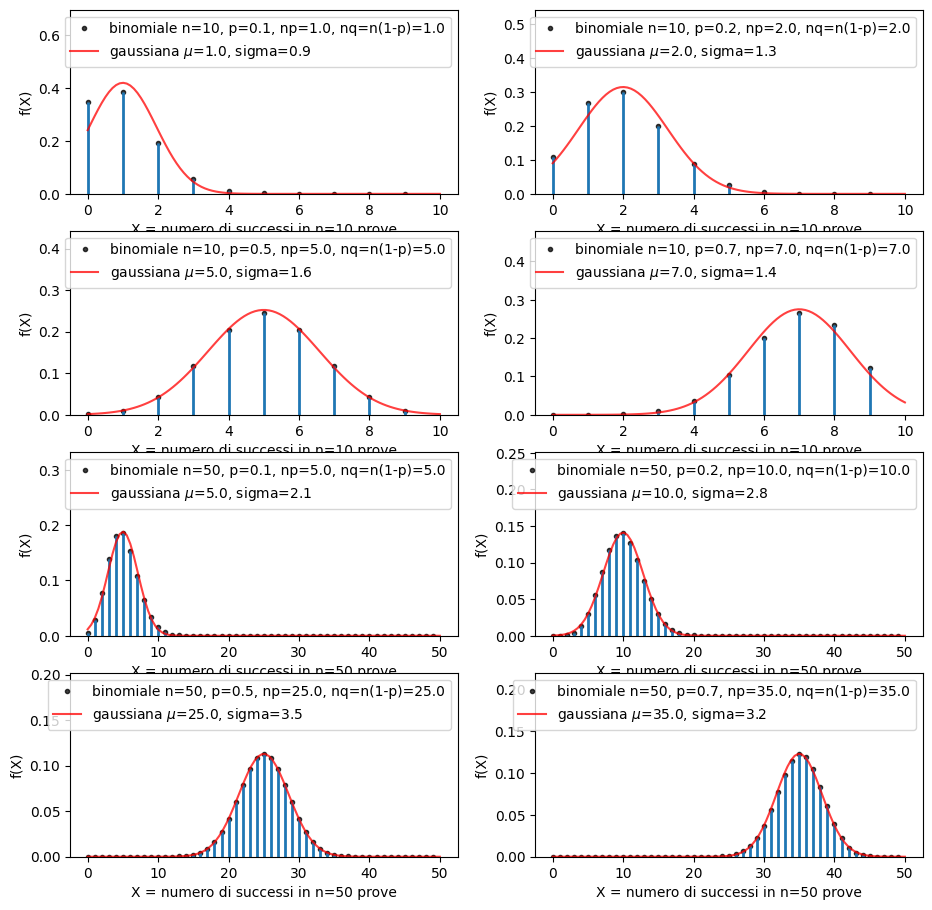

In [17]:
plt.figure(1, [11, 11])
plt.subplot(421)
confronto(n=10, p=0.1)
plt.subplot(422)
confronto(n=10, p=0.2)
plt.subplot(423)
confronto(n=10, p=0.5)
plt.subplot(424)
confronto(n=10, p=0.7)

plt.subplot(425)
confronto(n=50, p=0.1)
plt.subplot(426)
confronto(n=50, p=0.2)
plt.subplot(427)
confronto(n=50, p=0.5)
plt.subplot(428)
confronto(n=50, p=0.7)


## Random walk

In [18]:
p = 0.5             # probbilità di andare a sinistra o a destra
n = 50              # numero di passi
s = np.arange(0, n) # passi a sinistra
x = 2*s - n         # posizione

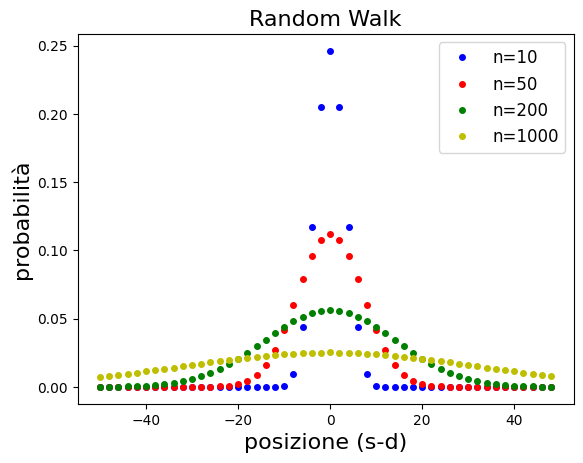

In [19]:

n=10
plt.plot(x, binom.pmf((x+n)/2, n, p), 'b.', ms=8, label='n={0:1d}'.format(n))

n=50
plt.plot(x, binom.pmf((x+n)/2, n, p), 'r.', ms=8, label='n={0:1d}'.format(n))


n=200
plt.plot(x, binom.pmf((x+n)/2, n, p), 'g.', ms=8, label='n={0:1d}'.format(n))


n=1000
plt.plot(x, binom.pmf((x+n)/2, n, p), 'y.', ms=8, label='n={0:1d}'.format(n))

plt.title('Random Walk',fontsize=16)
plt.xlabel("posizione (s-d)", fontsize=16)
plt.ylabel("probabilità", fontsize=16)
plt.legend(fontsize=12)


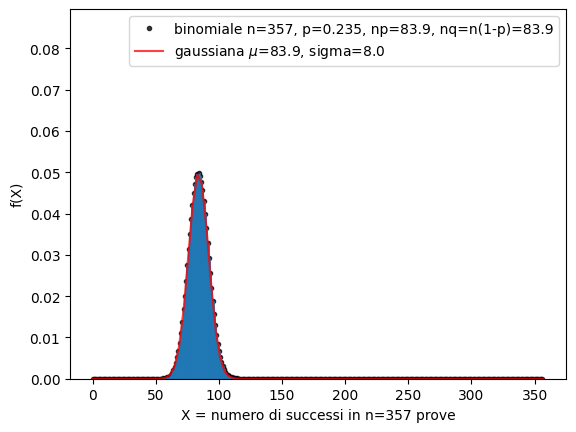

In [20]:
# esempio
confronto(n=357, p=0.235)

# Inferenza Binomiale
Immaginiamo di avere un processo di Bernoulli governato da una probabilità di successo $p$ ingnota; di esegure un certo numero $n$ di osservazioni e di aver riscontrato un numero $x$ di successi. Alla luce di queste osservazioni siamo interessati ad inferire $p$.

Per semplicità cominciamo col descrivere le nostre osservazioni come un processo binomiale ed indichiamo la variabile casuale 'numero di successi' con $X$,  e con $x$ la sua specifica realizzazione in una osservazione (ovvero di aver eseguito esattamente $n$ osservazioni e di aver riscontrato $x$ successi).
La probabilità di una certa osservazione $x$ è data da:
\begin{equation}
\mathcal{B}(X=x|n,p).
\end{equation}

Ricordiamo che tramite il teorema di Bayes è possibile costruire la funzione di probabilità a posteriori per $p$ come:
\begin{equation}
f(p|X=x) = \frac{\mathcal{B}(X=x|n,p) \pi(p)}{\int_0^1 \mathcal{B}(X=x|n,p) \pi(p)dp} = \frac{p^x (1-p)^{n-x}\pi(p)}{\int_0^1  p^x (1-p)^{n-x}\pi(p)dp }
\end{equation}
a sinistra dell'uguale abbiamo omesso di riportare esplicitamente $n$ tra i condizionanti per non appesantire la notazione. Allo stesso mondo scriveremo $x$ invece di $X=x$. Infine, si è semplificato tra numeratore e denominatore il coefficiente binomiale.

Nel caso di prior $\pi(p)$ vaga, questo termine si semplifica tra numeratore e denominatore e non rimane cha calcolare la costante di normalizzazione valutando l'integrale a denominatore
\begin{equation}
I = \int_0^1  p^x (1-p)^{n-x}dp
\end{equation}
Questo integrale può essere ricondotto all'integrale notevole che definisce la funzione beta di Eulero:
\begin{equation}
B(r, s) = \int_0^1 t^{r-1}(1-t)^{s-1}dt = \frac{\Gamma(r)\Gamma(s)}{\Gamma(r+s)}
\end{equation}
con:
\begin{equation}
\Gamma(r) = \int_0^\infty t^{r-1}e^{-t}dt.
\end{equation}
Per $r \in \mathcal{N}$, vale $\Gamma(r)= (r-1)!$.

E dunque:
\begin{equation}
B(r, s) = \frac{(r-1)!(s-1)!}{(r+s-1)!}
\end{equation}

Per determinare $I$ si opera la seguente sostituzione: $r-1 = x$; $s-1=n-x$:
\begin{equation}
I = \frac{x!(n-x)!}{(n+1)!}.
\end{equation}
Dunque la funzione di densità di probabilità di $p$ è:
\begin{equation}
f(p|X=x, n) = \frac{(n+1)!}{x!(n-x)!} p^x(1-p)^{n-x}
\end{equation}
Utilizzando lo stesso integrale notevole si possono calcolare esplicitamente il valore atteso e la varianza di $p$:
\begin{eqnarray}
E[p] &=& \frac{x+1}{n+2} \\
Var[p] &=& \frac{(x+1)(n-x+1)}{(n+3)(n+2)^2} \\
&=& E[p](1-E[p]) \frac{1}{n+3}
\end{eqnarray}
Sottolineiamo che questo risultato è stato ottenuto nell'ipotesi di prior $\pi(p)$ ininfluente, ovvero vaga rispetto alle informazioni che otteniamo dalla verosimiglianza. Inoltre, nel limite di $n \to \infty$ si ritrovano i valori $E[p]= x/n$, $Var[p] = E[p](1-E[p])/n$  che ci si aspetta da considerazioni intuitive.

E' interessante rappresentare graficamente $f(p|X=x, n)$, questa funzione di densità di probabilità si chiama funzione Beta ed è disponibile in scipy.stats.

Dal punto di vista qualitativo l'analisi grafica è piuttosto semplice:

- la funzione e' simmetrica per lo scambio di $p$ in $1-p$ e $x$ in $n-x$;
- se $x=0$, la funzione è monotona decrescente. Equivalentemente, per $x=n$ la funzione è monotona crescente;
- per $x$ generico la funzione avrà un massimo prodotto da i due termini che compentono: $p^x$ e $(1-p)^{n-x}$.


In [21]:
# funzione beta scritta esplicitamente
def p_post(p, n, x):
  return math.factorial(n+1)/math.factorial(x)/math.factorial(n-x) * np.power(p, x) * np.power(1-p, n-x)

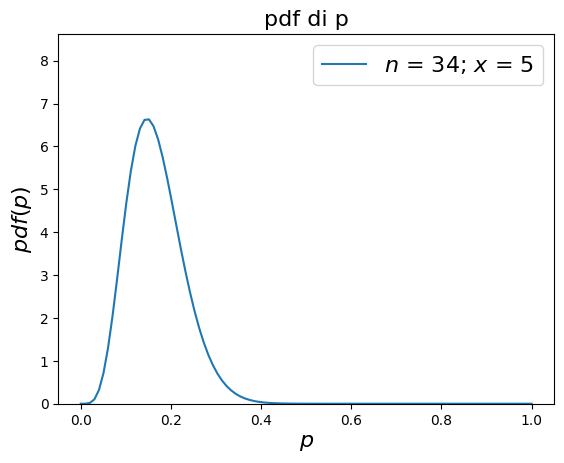

In [22]:
# provate a modificare i parametri n e x della distribuzione

n = 34
x = 5
p = np.linspace(0,1,100)
pdf = p_post(p, n, x)
plt.plot(p, pdf,
         label='$n$ = {0:1d}; $x$ = {1:1d}'.format(n,x))
plt.title('pdf di p', fontsize=16)
plt.xlabel('$p$',fontsize=16)
plt.ylim(0, 1.3*max(pdf))
plt.ylabel('$pdf(p)$',fontsize=16)
plt.legend(loc='upper right',fontsize=16)

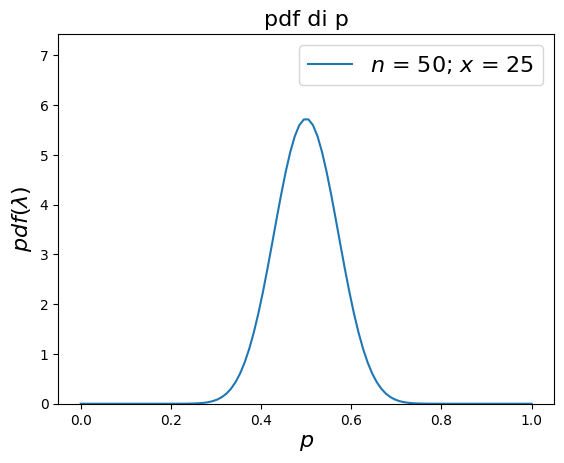

In [23]:
# fuzione beta di scypy

n = 50
x = 25
r = x+1
s = n-x+1
p = np.linspace(0,1,100)

# funzione beta
beta = sp.stats.beta(r, s)

# pdf
pdf = beta.pdf(p)
plt.plot(p, pdf,
         label='$n$ = {0:1d}; $x$ = {1:1d}'.format(n,x))
plt.title('pdf di p', fontsize=16)
plt.xlabel('$p$',fontsize=16)
plt.ylim(0, 1.3*max(pdf))
plt.ylabel('$pdf(\lambda)$',fontsize=16)
plt.legend(loc='upper right',fontsize=16)



In [24]:
print('Beta di par n = {0:1d}, x = {1:1d}'.format(n,x))
print('valore atteso       = {0:.3f};    x/n = {1:.3f}'.format(beta.mean(), (x)/(n)))
print('deviazione standard = {0:.3f};    sqrt(x/n(1-x/n)/n) = {1:.3f}'.format(beta.std(), np.sqrt(x/n*(1-x/n)/n)))


Beta di par n = 50, x = 25
valore atteso       = 0.500;    x/n = 0.500
deviazione standard = 0.069;    sqrt(x/n(1-x/n)/n) = 0.071




# Distribuzione di Poisson

La distribuzione di Poisson può essere ottenuta come limite della distribuzione binomiale per $n \to \infty, ~ np = \lambda$.
Dal punto di vista fisico possiamo intendere questa operazione di limite come conteggio di successi in *atti emlentari di osservazione*. Per praticità immaginiamo di studiare un fenomeno che si sviluppi nel tempo.  

In [25]:
from scipy.stats import poisson

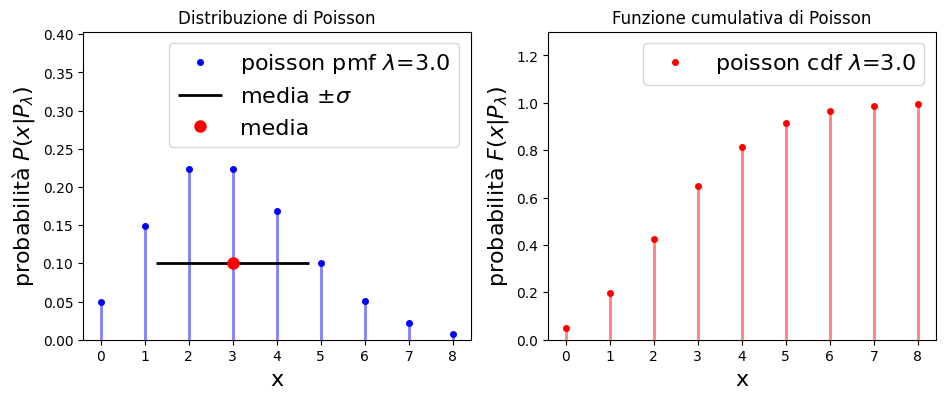

In [26]:
# parametro lambda della poissoniana
l = 3.0

n =  l*2+3
x = np.arange(0, n)
p=poisson(mu=l)
mean = l
sd = np.sqrt(l)
plt.figure(1, [11, 4])
plt.subplot(121)
# grafico della pmf
plt.plot(x, p.pmf(x), 'bo', ms=4,
         label='poisson pmf $\lambda$={0:.1f}'.format(l))
plt.vlines(x, 0, p.pmf(x), colors='b', lw=2, alpha=0.5)
# grafico di media e sd
plt.hlines(0.1, mean-sd, mean+sd,
           colors='black', lw=2, label='media $\pm \sigma$')
plt.plot(mean, 0.1, 'ro', ms=8, label='media')
plt.title('Distribuzione di Poisson')
plt.xlabel("x", fontsize=16)
plt.ylabel("probabilità $P(x| P_{\lambda})$", fontsize=16)
plt.legend( fontsize=16)
t = plt.xticks(x)
plt.ylim(0, np.max(p.pmf(x))*1.8)

plt.subplot(122)
plt.plot(x, p.cdf(x), 'ro', ms=4,
         label='poisson cdf $\lambda$={0:.1f}'.format(l))
plt.vlines(x, 0, p.cdf(x), colors='r', lw=2, alpha=0.5)
plt.title('Funzione cumulativa di Poisson')
plt.xlabel("x", fontsize=16)
plt.ylabel("probabilità $F(x| P_{\lambda})$", fontsize=16)
plt.ylim(0, 1.3)
plt.legend( fontsize=16)
t = plt.xticks(x)

In [27]:
def limite_poiss(l=1, n=10):
    p = l/n
    mean = l
    sigma = np.sqrt(n*p*(1-p))
    xmin = 0
    xmax = l*2+5
    pois=poisson(mu=l)
    x = np.arange(xmin, xmax)
    plt.plot(x, stats.binom.pmf(x, n, p), marker=".",
        color='black', alpha=0.75, linestyle='none',
        label=r'binomiale n={0}, p={1}, np={2:.1f}'.format(n,p,mean))
    plt.vlines(x, 0, stats.binom.pmf(x, n, p), lw=2)

    plt.plot(x+0.1, pois.pmf(x), 'bo', ms=4,
             label='poisson pmf $\lambda$={0:.1f}'.format(l))
    plt.vlines(x+0.1, 0, pois.pmf(x), colors='b', lw=2, alpha=0.5)

    x_gaus = np.linspace(xmin, xmax, 100)
    plt.plot(x_gaus, stats.norm.pdf(x_gaus, mean, sigma), linestyle="-",
        color='red', alpha=0.75,
        label=r'gaussiana $\mu$={0:.1f}, sigma={1:.1f}'.format(mean, sigma))
    plt.ylim(0, 2.3*np.max(stats.binom.pmf(x, n, p)))
    plt.xlabel('X = numero di successi in n={0} prove'.format(n))
    plt.ylabel('f(X)')
    plt.legend(loc='upper right')
    #plt.xlim(0, 50)


/Users/leticiacunqueiro/.pyenv/versions/3.9.2/lib/python3.9/site-packages/scipy/stats/_distn_infrastructure.py:1986: RuntimeWarning: divide by zero encountered in divide
  x = np.asarray((x - loc)/scale, dtype=dtyp)


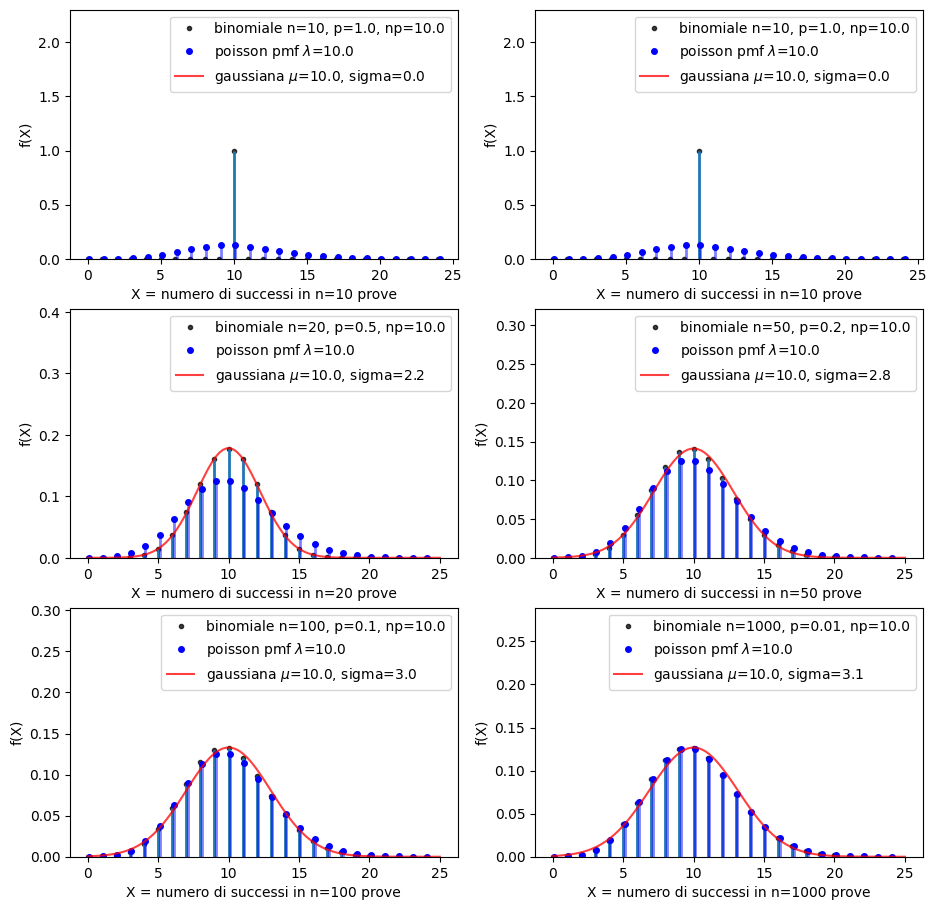

In [28]:
l = 10
plt.figure(1, [11, 11])
plt.subplot(321)
limite_poiss(l=l, n=np.maximum(5,l))
plt.subplot(322)
limite_poiss(l=l, n=np.maximum(10,l))
plt.subplot(323)
limite_poiss(l=l, n=np.maximum(20, l))
plt.subplot(324)
limite_poiss(l=l, n=50)
plt.subplot(325)
limite_poiss(l=l, n=100)
plt.subplot(326)
limite_poiss(l=l, n=1000)


## Funzione di verosimiglianza Poissoniana
Ricordiamo che la funzione di verosimiglianza non e' niente altro che la funzione di probabilità $P(x|\lambda)$ delle osservazioni (in questo caso $x$) vista come funzione del parametro di interesse $\lambda$ ad osservazioni fissate $x=x_0$. In sostanza dopo aver osservato $x=x_0$ ci domandiamo quale sia l'andamento di  $P(x=x_0|\lambda)$ in funzione del parametro $\lambda$.

La funzione di verosimiglianza è un ingrediente fondamentale per costruire la funzione $p(\lambda|x=x_0)$, ovvero la funzione di probabilità di $\lambda$ condizionata al valore osservato $x=x_0$.

La differenza fondamentale tra la $p(\lambda|x=x_0)$ e la funzione di  verosimiglianza di $\lambda$, che indicheremo con $\mathcal{L}(\lambda; x=x_0)$, è che la prima è normalizzata ad 1 essendo una funzione di densità di probabilità, la seconda in generale non lo è.


In [29]:
# definiamo la nostra funzione di verosimiglianza poissoniana
def l_pois(l,x=0):
  return poisson.pmf(x, l)

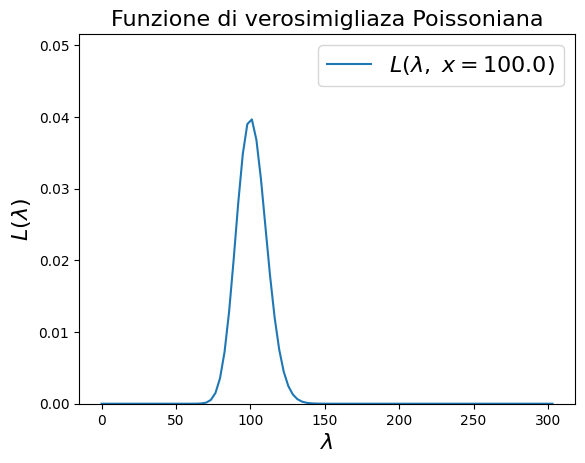

In [30]:
# assumiamo di aver osservato x e di essere interessati
# a rappresentare l(lambda; x)
x=100
l = np.linspace(0, x*3+3, 100)
plt.plot(l, l_pois(l,x), label='$L(\lambda,~x={0:.1f})$'.format(x))
plt.title('Funzione di verosimigliaza Poissoniana', fontsize=16)
plt.xlabel('$\lambda$',fontsize=16)
plt.ylim(0, 1.3*max(l_pois(l=l,x=x)))
plt.ylabel('$L(\lambda)$',fontsize=16)
plt.legend(loc='upper right',fontsize=16)


## inferenza poissoniana
Ricordiamo che tramite il teorema di Bayes è possibile costruire la funzione di probabilità a posteriori per $\lambda$ $p(\lambda|x=x_0)$ come:
\begin{equation}
p(\lambda|x=x_0) = \frac{\mathcal{L}(\lambda; x=x_0) \pi(\lambda)}{\int_0^\infty \mathcal{L}(\lambda; x=x_0) \pi(\lambda)d\lambda}
\end{equation}
nel caso di prior $\pi(\lambda)$ vaga, questo termine si semplifica tra numeratore e denominatore e non rimane cha calcolare la costante di normalizzazione valutando l'integrale a denominatore
\begin{equation}
\int_0^\infty \frac{e^{-\lambda}\lambda^{x_0}}{x_0!} d\lambda = 1
\end{equation}
Possiamo verificare numericamente che l'integrale della verosimiglianza faccia effettivamente 1.

Dunque nel caso di inferenza poissioniana con prior uniforme la posterior è uguale alla verosimiglianza.

In [31]:
# libreria per integrazione numerica
import scipy.integrate as integrate

In [32]:
# questa funzione fornisce il valore dell'integrale e
# la relativa incertezza
integrate.quad(l_pois, 0, math.inf)

(1.0000000000000002, 5.842606742906004e-11)

Possiamo utilizzare questo metodo di integrazione numerica per costruire la funzione cumulativa della posterior
\begin{equation}
F(\lambda) = \int_0^\lambda \frac{e^{-\lambda^\prime}{\lambda^\prime}^x}{x!} d\lambda^\prime
\end{equation}

In [33]:
# args nel metodo quad definisce i valori
# dei parametri della funzione da integrare
def cumulativa_posterior(l, x=0):
  i, e = integrate.quad(l_pois, 0, l, args=(x,))
  return i
vcum = np.vectorize(cumulativa_posterior)

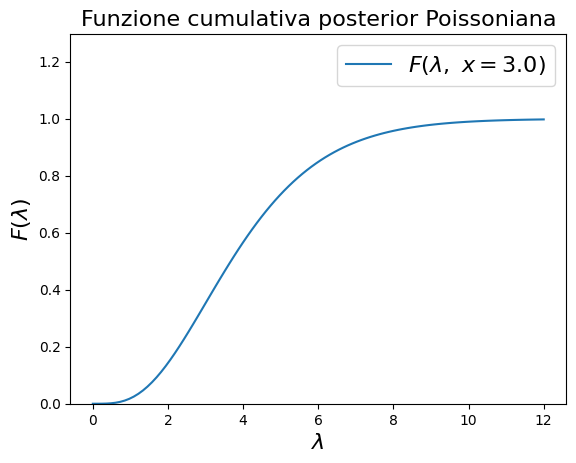

In [34]:
x=3
l = np.linspace(0, x*3+3, 100)
plt.plot(l, vcum(l, x), label='$F(\lambda,~x={0:.1f})$'.format(x))
plt.title('Funzione cumulativa posterior Poissoniana', fontsize=16)
plt.xlabel('$\lambda$',fontsize=16)
plt.ylim(0, 1.3*max(vcum(l=l,x=x)))
plt.ylabel('$F(\lambda)$',fontsize=16)
plt.legend(loc='upper right',fontsize=16)


Da questo grafico si vede come la funzione di probabilità a posteriori $f(\lambda|x)$ è normalizata ad 1.

Per il calcolo di valore atteso e varianza di $\lambda$ possiamo calcolare direttamente gli integrali definiti:
\begin{eqnarray}
E[\lambda] &=& \int_0^\infty\lambda f(\lambda|x)\, d\lambda \\
E[\lambda^2] &=& \int_0^\infty\lambda^2 f(\lambda|x)\, d\lambda \\
\sigma[\lambda] &=& \sqrt{E[\lambda^2] -
E[\lambda]^2}
\end{eqnarray}

In [35]:
# un funzione che moltiplica la pdf (in questo caso coincide con
# la verosimiglianza per la potenza 'm' di lambda=l.
# di fatto l'argomento dell'integrale del momento di ordine m intorno a zero.
def arg_mom(l, x=0, m=0):
  return np.power(l, m) * l_pois(l, x=x)

# calcolo in momento di ordine m
def E_lambda_m(x=0, m=0):
  i, e = integrate.quad(arg_mom, 0, math.inf, args=(x, m))
  return i


In [36]:
# valore atteso e' il momento di ordine 1
El = E_lambda_m(m=1, x=10)
El

10.999999999999996

In [37]:
# valore atteso di l^2
El_square = E_lambda_m(m=2, x=10)
El_square

131.99999999999991

In [38]:
# la deviazione standard e'
np.sqrt(El_square - El**2)

3.3166247903553976

### Inferenza poissoniana tramite la funzione gamma

Tutti questi risultati si possono ottenere in maniera più efficente osservando che la posterior $f(\lambda|x)$ può essere espressa in termini della funzione di densità di probabilità [gamma](https://https://en.wikipedia.org/wiki/Gamma_distribution), definita come:
 $$
 \gamma(\lambda | \alpha, \beta) = \frac{\beta^\alpha}{\Gamma(\alpha)} \lambda^{\alpha-1} e^{-\beta \lambda}
 $$
 questa è una funzione di 2 parametri $\alpha$ e $\beta$ detti rispettivamente  'shape' e 'rate'. Il valore atteso e la deviazione standard sono:
\begin{eqnarray}
E[\lambda] &=& \frac{\alpha}{\beta}\\
\sigma[\lambda] &=& \frac{\sqrt{\alpha}}{\beta}
\end{eqnarray}
  Prende il nome dalla gamma di Eulero rappresentando l'argomento dell'integrale a meno di una costante di normalizzazione:
 $$
 \Gamma(z) = \int_0^\infty x^{z-1} e^{-x} dx
 $$
 che per $z \in \mathcal{N}$,  $\Gamma(z) = (z-1)!$.

 Per utilizzare la gamma nell'inferenza poissoniana basta osservare che la posterior soddisfa:
 $$
 f(\lambda| x ) \propto e^{-\lambda} \lambda^x \propto \gamma(\lambda | \alpha = x+1, \beta = 1)
 $$

 Da questa relazione è immediato ottenere il valore atteso e la deviazione standard di $\lambda$:
\begin{eqnarray}
E[\lambda] &=& x+1\\
\sigma[\lambda] &=& \sqrt{x+1}
\end{eqnarray}

La semplificazione notevole risiede nel fatto che python ha la funzione di densità di probabilità gamma già implementata.

In [39]:
# la funzione gamma di scipy.stats ha il parametro 'a' che corrisponde ad alpha ed il paramtro scale
# di default pari ad 1 che corrisponde ad 1/beta
from scipy.stats import gamma

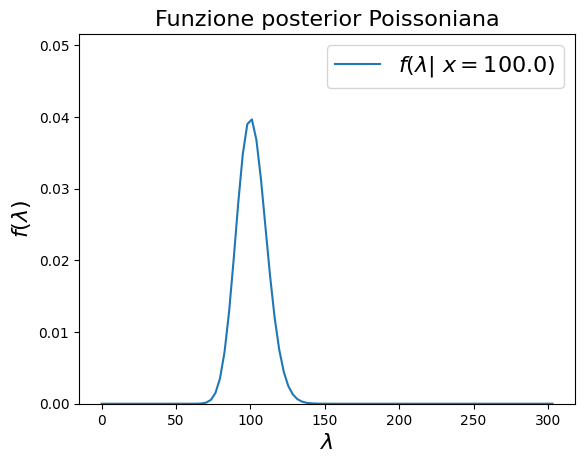

In [40]:
# supponiamo di aver osservato x conteggi
# e di volere la posterior su lambda (indicato di seguito con l)
x=100
l = np.linspace(0, x*3+3, 100)
plt.plot(l, gamma.pdf(l, a=x+1), label='$f(\lambda|~x={0:.1f})$'.format(x))
plt.title('Funzione posterior Poissoniana', fontsize=16)
plt.xlabel('$\lambda$',fontsize=16)
plt.ylim(0, 1.3*max(gamma.pdf(l, a=x+1)))
plt.ylabel('$f(\lambda)$',fontsize=16)
plt.legend(loc='upper right',fontsize=16)


In [41]:
# per media e varianza
mean, var = gamma.stats(a=x+1, moments='mv')
print('media               = ', mean)
print('deviazione standard = ', np.sqrt(var))

media               =  101.0
deviazione standard =  10.04987562112089


## Esempio di inferenza poissoniana
Supponiamo di effettuare una misura di conteggio di un certo fenomeno governato da una distribuzione di probabilità poissoniana di parametro $\lambda$.
Possiamo simulare questa misura generando un numero random con probabilità data dalla poissoniana $P(x | \lambda)$. Alla luce dell'osservazione $x$ vogliamo dare la funzione di probabilità a posteriori di $\lambda$. Assumiamo che la distribuzione a priori $\pi(\lambda)$ sia uniforme entro l'intervallo sondato dalla verosimiglianza. Avremo per la posterior
$$
f(\lambda | x) = \gamma(\lambda | x+1, 1) \propto \mathcal{L}(\lambda; x)
$$
che sappiamo rappresentare graficamente.

### Caso di singola osservazione

TypeError: annotate() missing 1 required positional argument: 'text'

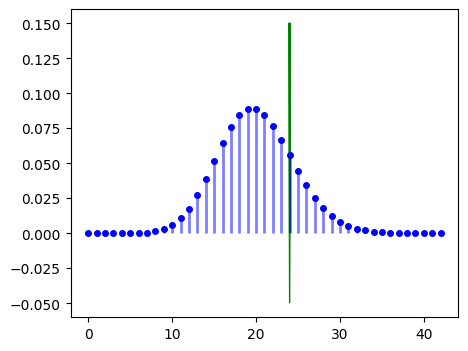

In [42]:
# si puo' modificare il valore di lambda iniziale
l = 20


n =  l*2+3
x = np.arange(0, n)
p=poisson(mu=l)
mean = l
sd = np.sqrt(l)
# simulo una misura estraendo un valore random
m = p.rvs(size=1)[0]

#grafici
plt.figure(1, [11, 4])
plt.subplot(121)
# grafico della pmf
plt.plot(x, p.pmf(x), 'bo', ms=4, label='poisson pmf $\lambda$={0:.1f}'.format(l))
plt.vlines(x, 0, p.pmf(x), colors='b', lw=2, alpha=0.5)
plt.arrow(m, 0.0, 0.0, -0.05, length_includes_head=True, color='g',
          head_width=0.2, head_length=0.2, head_starts_at_zero=False)
plt.annotate(xy=(m+0.1, 0.2), s='mis. x={0:1d}'.format(m), fontsize=16)
# grafico di media e sd
plt.hlines(0.1, mean-sd, mean+sd, colors='black', lw=2, label='media $\pm \sigma$')
plt.plot(mean, 0.1, 'ro', ms=8, label='media')
plt.title('Distribuzione di Poisson',  fontsize=16)
plt.xlabel("x", fontsize=16)
plt.ylabel("probabilità $P(x| P_{\lambda})$", fontsize=16)
plt.legend( fontsize=16)
t = plt.xticks(x)
plt.ylim(0, np.max(p.pmf(x))*2)

plt.subplot(122)
x=m
l = np.linspace(0, x*4+3, 100)
plt.plot(l, gamma.pdf(l, a=x+1), label='$f(\lambda|~x={0:.1f})$'.format(x))
plt.title('Funzione posterior Poissoniana', fontsize=16)
plt.xlabel('$\lambda$',fontsize=16)
plt.ylim(0, 1.5*max(gamma.pdf(l, a=x+1)))
plt.ylabel('$f(\lambda)$',fontsize=16)
plt.legend(loc='upper right',fontsize=16)
mean, var = gamma.stats(a=x+1, moments='mv')
sd = np.sqrt(var)
plt.hlines(0.1, mean-sd, mean+sd, colors='black', lw=2, label='$\sigma[\lambda]=${0:.1f}'.format(sd))
plt.plot(mean, 0.1, 'ro', ms=8, label='E[$\lambda$]={0:.1f}'.format(mean))
plt.legend(loc='upper right',fontsize=16)
txt = "La freccia verde indica il valore misurato"
plt.figtext(0.5, -0.1, txt, wrap=True, horizontalalignment='center', fontsize=16)


### Caso di osservazioni multiple
In questo caso si fanno un numero di osservazioni $n_{mis}$ dello stesso fenomeno poissoniano e si è interessati a determinare $\lambda$.

La maniera più semplice di procedere consiste nello sfruttare le proprietà riproduttiva rispetto alla somma della poissoniana e considerare di aver fatto un unica osservazione:
$$
x_{eq} = \sum_{i=1}^{n_{mis}} x_i
$$
con
$$ x_{eq} \sim \mathcal{P}(\lambda_{eq} = n_{mes}\cdot \lambda)
$$
Si procede dunque a fare inferenza su $\lambda_{eq}$ e poi si torna in dietro alla variabile di interesse $\lambda = \lambda_{eq}/n$ con un semplice cambio di variabili, ottenendo:
$$
f(\lambda_{eq} |\{x_1,\dots, x_{n_{mes}}\}) = \gamma(\lambda_{eq} \,|\, 1+\sum_{i=1}^{n_{mis}} x_i,\, 1)
$$
da cui
$$
E[\lambda_{eq}] = 1+ \sum_{i=1}^{n_{mis}}
 x_i
$$
ed infine, operando il cambio di variabile

\begin{eqnarray}
E[\lambda] &=& \frac{ 1+ \sum_{i=1}^{n_{mis}} x_i}{n_{mes}}\\
\sigma[\lambda] &=& \frac{\sqrt{1+ \sum_{i=1}^{n_{mis}} x_i}}{n_{mes}} = \sqrt{\frac{E[\lambda]}{n_{mes}}}
\end{eqnarray}

Da cui si realizza come l'incertezza su $\lambda$  diminuisca come $1/\sqrt{n_{mes}}$ all'aumentare del numero di misure $n_{mes}$.

In alternativa si può direttamente scrivere la pdf di $\lambda$ come una gamma utilizzando il parametro $\beta=n_{mes}$:
$$
f(\lambda |\{x_1,\dots, x_{n_{mes}}\}) = \gamma(\lambda \,|\, 1+\sum_{i=1}^{n_{mis}} x_i,\, n_{mes})
$$
Quest'ultima strategia è di più facile implementazione come si vede nelle celle di codice qui sotto.

In [ ]:
# si puo' modificare il valore di lambda iniziale
l = 3
p=poisson(mu=l)
# si puo' modificare il numero di misure n_mis
n_mis = 50


n =  l*2+3
x = np.arange(-0.5, n-0.5)
mean = l
sd = np.sqrt(l)
# simulo n_mis misure estraendo valori random
m = p.rvs(size=n_mis)

# rappresento l'istogramma delle frequenze relative
# e lo confronto con la pmf

plt.hist(m, bins=x, density=True)

x = np.arange(0, n)
# grafico della pmf
plt.plot(x, p.pmf(x), 'bo', ms=4,
         label='poisson pmf $\lambda$={0:.1f}'.format(l))
plt.vlines(x, 0, p.pmf(x), colors='b', lw=2, alpha=0.5)
# grafico di media e sd
plt.hlines(0.1, mean-sd, mean+sd,
           colors='black', lw=2, label='media $\pm \sigma$')
plt.plot(mean, 0.1, 'ro', ms=8, label='media')
plt.title('Distribuzione di Poisson',  fontsize=16)
plt.xlabel("x", fontsize=16)
plt.ylabel("probabilità $P(x| P_{\lambda})$", fontsize=16)
plt.legend( fontsize=16)
t = plt.xticks(x)
plt.ylim(0, np.max(p.pmf(x))*2)

Per l'inferenza su $\lambda$ abbiamo:

In [ ]:
x=sum(m)
l = np.linspace(0, (x*3+3)/n_mis, 100)
plt.plot(l, gamma.pdf(l, a=x+1, scale=1/n_mis),
         label='$f(\lambda|~\sum x_i=${0:.1f})'.format(x))
plt.title('Funzione posterior Poissoniana', fontsize=16)
plt.xlabel('$\lambda$',fontsize=16)
plt.ylim(0, 1.5*max(gamma.pdf(l, a=x+1, scale=1/n_mis)))
plt.ylabel('$f(\lambda)$',fontsize=16)
plt.legend(loc='upper right',fontsize=16)
mean, var = gamma.stats(a=x+1, scale=1/n_mis, moments='mv')
sd = np.sqrt(var)
plt.hlines(0.1, mean-sd, mean+sd,
           colors='black', lw=2,
           label='$\sigma[\lambda]=${0:.2f}'.format(sd))
plt.plot(mean, 0.1, 'ro', ms=8,
         label='E[$\lambda$]={0:.2f}'.format(mean))
plt.legend(loc='upper right',fontsize=16)

Infine, notiamo come la posterior $f(\lambda)$ sia praticamente gaussiana a partire da $x\sim 10$.

# Distribuzione multinomiale
La distribuzione di probabilità multinomiale è una distribuzione di più variabili casuali. Questa distribuzione descrive l'osservazione di $n$ eventi indipendenti, dove ciascun evento può realizzarsi secondo $m$ modalità esclusive, ciascuna di probabilità $p_i$, con:
$$
\sum_{i=1}^m p_i = 1.
$$
Sia $x_i$ il numero di realizzazioni della modalità $i$, si ha che:
$$
\sum_{i=1}^m x_i= n.
$$
La distribuzione di probabilità del vettore aleatorio $\vec{x} = (x_1,x_2\dots, x_m)$, di parametri $\vec{p} =(p_1, p_2\dots, p_m), m, n$, è data da:
$$
f(\vec{x},\mathcal{M}_{n,\vec{p}}^m) = n!\prod_{i=0}^m \frac{p_i^{x_i}}{x_i!}
$$
Questa espressione non è niente altro che il prodotto delle probabilità dei singoli eventi ragguppati secondo le $m$ modalità di realizzazione. Il coefficiente multinomiale rappresenta il numero di combinazioni semplici  possibili con cui si possono organizzare $n$ eventi in modo da avere esattamente $x_1$ eventi realizzati secondo la prima modalità, $x_2$ secondo la seconda e così via. Per convincersi ulteriormente di questa interpretazione si provi a descrivere una distribuzione binomiale di parametri $p,n$ in termini di 2 variabili $x_1$ numero di successi con probabilità $p_1=p$ e $x_2=n-x_1$ numero di insuccessi con prbabilità $p_2=1-p$ (osservando che le variabili $x_1$ e $x_2$ sono completamente anticorrelate con $\rho=-1$ essendo, a meno di una costante la stessa variabile). Continuando con questa analogia, se si è interessati al comportamento di una delle $x_i$, è sempre possibile immaginare la distribuzione multinomiale come una binomiale nella variabile $x_i$ combinando tutte le altre $x_j\,(j\neq j)$ in una unica modalità equivalente al complementare di $x_i$. Questa analogia ci consente di determinare il valore atteso e la varianza di $x_i$:
\begin{eqnarray}
E[x_i] &=& np_i,\\
Var[x_i] &=& np_i(1-p_i).
\end{eqnarray}
A queste quantità si aggiunge la covarianza tra coppie di $x_i$ e $x_j$. Secondo l'analogia con la distribuzione binomiale nel caso di due sole variabili possiamo aspettarci:
\begin{eqnarray}
Cov[x_i, x_j] &=& -np_ip_j,\\
Corr[x_i, x_j] &=& \frac{Cov[x_i, x_j]}{\sqrt{Var[x_i]Var[x_j]}}\\
&=& -\sqrt{\frac{p_ip_j}{(1-p_i)(1-p_j)}}
\end{eqnarray}
Le relazioni precedenti sono valide per $i\neq j$, altrimenti:
$$
Cov[x_i, x_i] \equiv Var[x_i] = np_i(1-p_i).
$$

## Calcolo esplicito della covarianza
Per il calcolo della covarianza sfuttiamo la relazione:
$$
Cov[x_i, x_j] = E[x_ix_j] - E[x_i]E[x_j].
$$
Ricordando la relazione di completezza:
\begin{eqnarray}
\sum_{x_1,x_2,\dots, x_m = 0 \\ x_1+x_2+\dots + x_m = n}^n \frac{n!}{x_1!x_2!\dots x_m!} p_1^{x_1}p_2^{x_2}\dots p_m^{x_p} = (p_1+p_2+\dots+p_m)^n=1
\end{eqnarray}
Per semplicità calcoliamo il caso $i=1, j+2$:
\begin{eqnarray}
E[x_i x_j] &=& \sum_{x_1,x_2,\dots, x_m = 0 \\ x_1+x_2+\dots + x_m = n}^n
x_1x_2\frac{n!}{x_1!x_2!\dots x_m!} p_1^{x_1}p_2^{x_2}\dots p_m^{x_p} \\
&=& p_1p_2 \sum_{x_1,x_2,\dots, x_m = 0 \\ x_1+x_2+\dots + x_m = n}^n
\frac{n!}{(x_1-1)!(x_2-1)!\dots x_m!} p_1^{x_1-1}p_2^{x_2-1}\dots p_m^{x_p} \\
&=& p_1p_2 \sum_{x_1^\prime,x_2^\prime,\dots, x_m = 0 \\ x_1^\prime+x_2^\prime+\dots + x_m = n-2}^{n-2}
\frac{n!}{x_1^\prime!x_2^\prime!\dots x_m!} p_1^{x_1^\prime}p_2^{x_2^\prime}\dots p_m^{x_p} \\
&=& n(n-1)p_1p_2 \sum_{x_1^\prime,x_2^\prime,\dots, x_m = 0 \\ x_1^\prime+x_2^\prime+\dots + x_m = n-2}^{n-2}
\frac{(n-2)!}{x_1^\prime!x_2^\prime!\dots x_m!} p_1^{x_1^\prime}p_2^{x_2^\prime}\dots p_m^{x_p} \\
&=& n(n-1)p_1p_2 \sum_{x_1^\prime,x_2^\prime,\dots, x_m = 0 \\ x_1^\prime+x_2^\prime+\dots + x_m = n^\prime}^{n^\prime}
\frac{n^\prime!}{x_1^\prime!x_2^\prime!\dots x_m!} p_1^{x_1^\prime}p_2^{x_2^\prime}\dots p_m^{x_p} \\
&=& n(n-1)p_1p_2
\end{eqnarray}
Da cui:
$$
Cov[x_i, x_j] = n(n-1)p_1p_2 - n^2p_1p_2 = -np_1p_2
$$

## Inferenza multinomiale nel caso del 'pallinometro'
Il pallinometro è costituito da una serie di file di chiodi identici. Una pallina che urta un chiodo potrà andare a destra con probabilità $p$ e a sinistra con probabilità $1-p$. L'evento associato all'urto pallina-chiodo è dunque un evento di Bernoulli di probabilità $p$. I chiodi sono disposti in maniera tale che una pallina reduce da un urto con il chiodo della fila $i-1$ si troverà ad urtare un chiodo della fila $i$ e così via fino a superare tutte le file disponibili e raggiungere la casella finale $k$. E' facile convincersi che, date $n$ file, il numero di caselle accessibili è $0\leq k\leq n$. La pallina cadrà nella casella 0 se sarà andata a sinistra ad ogni collisione con i chiodi, nella casella 1 se in una sola collisione sarà andata a destra, e così via fino a raggiungere la casella $n$ se sarà andata sempre a destra.

La probabilità $f(k|\mathcal{B}_{p,n})$ con cui la pallina raggiunge la casella $k$ è dunque determinata da una distribuzione binomiale di parametri $p$ e $n$:
$$
f(k|\mathcal{B}_{p,n}) = \binom{n}{k}p^k(1-p)^{n-k}
$$
Nel caso in cui si lanciassero $m$ palline, la probabilità di trovare $x_k$ palline nella casella $k$ è data dalla distribuzione multinomiale:
\begin{eqnarray}
f(\vec{x}|\mathcal{M}^m_{n,f(k|\mathcal{B}_{p,n})}) &=& \frac{m!}{x_1!x_2!\dots x_n!}\prod_{k=0}^{n} [f(k|\mathcal{B}_{p,n})]^{x_k} \\
&=& \frac{m!}{x_1!x_2!\dots x_n!}\prod_{k=0}^{n} \left[\binom{n}{k}\right]^{x_k}p^{k x_k}(1-p)^{(n-p)x_k} \\
\end{eqnarray}
La funzione di verosimiglianza è dunque:

\begin{eqnarray}
\mathcal{L}(p; \vec{x}) &\propto& p^{\sum_{k=0}^n kx_k}(1-p)^{\sum_{k=0}^n (n-k)x_k }\\
&=&p^{m\overline{k}}(1-p)^{m(n-\overline{k})}
\end{eqnarray}
dove si è definito:
$$
\overline{k} = \frac{\sum_{k=0}^n kx_k}{\sum_{k=0}^n x_k} = \frac{1}{m}\sum_{k=0}^n kx_k
$$
Questa funzione di verosimiglianza è equivalente alla funzione di verosimiglianza binomiale di paremetri $k^\prime = m\overline{k}$ e $n^\prime=mn$.
La funzione di probabilità a posteriori di $p$ si ottiene tramite inferenza binomiale:
$$
f(p|\vec{x}) \propto p^{m\overline{k}}(1-p)^{m(n-\overline{k})} \pi(p)
$$
che nel caso di prior $\pi(p)$ ininfluente puo' essere scritta:
$$
f(p|\vec{x}) = B(r=m\overline{k}+1, s=m(n-\overline{k})+1).
$$
Il valore atteso e la varianza di $p$ sono:
\begin{eqnarray}
E[p] &=& \frac{m\overline{k}+1}{mn+2} \simeq \frac{\overline{k}}{n}\\
Var[p] &=& \frac{E[p](1-E[p])}{mn+3} \simeq \frac{E[p](1-E[p])}{mn}.
\end{eqnarray}

### Derivazione alternativa
Per fare inferenza su $p$ nel caso del 'pallinometro' è possibile procedere in modo molto semplice seguendo un argomento intuitivo. Immaginiamo di seguire ciascuna pallina e di indicare con $i$ l'indice della pallina ($0\le i\le m$). Sia $k_i$ la casella finale associata alla pallina $i$-esima. Potremmo pensare al lancio di $m$ palline come la somma di $m$ variabili $k_i$ ciascuna con probabilità binomiale di parametri $(n,p)$. La variabile:
$$
j = \sum_{i=0}^m k_i
$$
avrà una distribuzione di probabilità binomiale di parametri $(p, \sum_{i=0}^m n=mn)$, grazie alla proprietà riproduttiva rispetto alla somma di variabili binomiali con la stessa $p$.
E' immediato ricavare valore atteso e varianza di $p$ tramite inferenza binomiale.

Questa descrizione può essere ulteriormente semplificata nel caso si sia solo interessati a inferire $p$, scomponendo la caduta di $m$ palline su $n$ file di chiodi come $mn$ urti indipendenti pallina-chiodo, tutti governati dalla stessa probabilità $p$, e dunque come $mn$ eventi di Bernoulli $x_j$. Di questi eventi si è interessati a studiare la variabile casuale data dalla media aritmentica:
$$
y = \frac{1}{mn}\sum_{j=0}^{mn}x_j
$$
da cui:
\begin{eqnarray}
E[y] &=& \frac{1}{mn}\sum_{j=0}^{mn}E[x_j] = \frac{1}{mn}\sum_{j=0}^{mn}p = p\\
Var[y] &=& \frac{1}{(mn)^2}Var[\sum_{j=0}^{mn} x_j] = \frac{1}{(mn)^2}\sum_{j=0}^{mn}Var[x_j] = \frac{p(1-p)}{mn}
\end{eqnarray}   


# Grafici in scala semi-logaritmica



In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import expon

x = np.linspace(0, 10, 100)
y = expon.pdf(x)

# plot size
plt.figure(figsize=(10,10))

# configure font
font = {'family' : 'sans-serif',
        'weight' : 'bold',
        'size'   : 16}

plt.rc('font', **font)

# Display grid
plt.grid(True, which="both")

# Linear X axis, Logarithmic Y axis
plt.semilogy(x, y, label='Distribuzione esponenziale' )
plt.semilogy(x, 2*np.exp(-x/4), label='$y = 2 exp(-x/4)$' )
plt.semilogy(x, 4*np.exp(-x/4), label='$y = 4 exp(-x/4)$' )
plt.semilogy(x,24*np.exp(-x/2), label='$y = 2 exp(-x/2)$' )
plt.semilogy(x, 2*np.power(10,-x/4), label='$y = 2 \cdot 10^{-x/4}$' )



plt.ylim([1e-4, 30])
plt.xlim([0, 10])

# Provide the title for the semilog plot
plt.title('Y axis in Semilog using Python Matplotlib')

# Give x axis label for the semilog plot
plt.xlabel('time')

# Give y axis label for the semilog plot
plt.ylabel('probability density')

# add legend
plt.legend()

# Display the semilog plot
plt.show()


## Proprietà delle scale logaritmiche

- la scala si infittisce in prossimità di $10^n$ poi si dirada.

- la distanza tra due punti che differiscono di un certo numero di ordini di grandezza è costante. Per esempio se $y_2 = 10^n y_1$:
$$
lny_2 - lny_1 = ln\frac{y_2}{y_1} = n \,ln10
$$
Gli itervalli tra potenze di 10 sono chiamati decadi e sono di lunghezza costante
- il valore 0 non può comparire in scala logaritmica poiché $lim_{x\to 0} log x = \infty$
- due rette parallele differiscono per una costante lungo le $x$ e di un fattore lungo le $y$
- le scale logaritmiche sono sempre in base 10. Questo non modifica il comportamento grafico di una legge esponenziale: ciò che è lineare in base $e$ è anche lineare in base 10 ($ln\,x = ln10 \,log\,x$).
- il è una funzione trascendente e quindi adimensionale.

# Distribuzione statistica

In [ ]:
from scipy.stats import poisson
def PrevisionePossion(Lambda, xmin, xmax, n):
    x = np.arange(xmin, xmax)
    k_list = []
    sigma_k_list = []
    for i in x:
        p_i = poisson.pmf(i, Lambda)
        k_list.append( n*p_i )
        sigma_k_list.append( math.sqrt( n * p_i * (1 - p_i) ) )
    k = np.asarray(k_list)
    sigma_k = np.asarray(sigma_k_list)
    return k, sigma_k

In [ ]:
from scipy.stats import poisson
import math
N_misure = 50
mylambda = 3
p=poisson(mu=mylambda)
xmin = 0
xmax = 8
Nbins= xmax-xmin
mycounts = p.rvs(size = N_misure)


# Disegna la distribuzione statistica = istogramma
# rappresento l'istogramma delle frequenze
plt.hist(mycounts, bins = Nbins,
         range = (xmin-0.5, xmax-0.5), label="Distribuzione statistica")

#plt.hist(m, bins=x, density=False, label ='distribuzione statistica')




# Calcola e disegna la previsione della distribuzione statistica
x_prev = np.arange(xmin, xmax)
# posso utilizzare la lambda teorica (quella con cui ho generato le misure)
this_lambda = mylambda
# o la lambda sperimentale data dalla media dei conteggi
this_lambda = np.mean(mycounts)
k_prev, sigma_k_prev = PrevisionePossion(this_lambda,xmin,xmax,N_misure)
plt.errorbar(x_prev,
             k_prev,
             yerr=sigma_k_prev,
             marker='o',markersize=3,linestyle='none',
             label="Previsione $\lambda = {0:.1f}$".format(this_lambda))

# assi e legenda
plt.title('Istogramma di n={0:2d} misure di conteggio'.format(N_misure))
plt.ylim(0, np.max(N_misure*p.pmf(x_prev))*2.5)
plt.xlabel("Conteggi")
plt.ylabel("Occorrenze")
plt.legend()